In [4]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from io import BytesIO

# Upload the book dataset
uploaded = files.upload()

# Read the uploaded CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(BytesIO(uploaded[file_name]))

# Display first five rows
print(df.head())


Saving CodeAlpha_Web_Scraping.csv to CodeAlpha_Web_Scraping.csv
                                   Title   Price Rating Availability
0                   A Light in the Attic  £51.77  Three     In stock
1                     Tipping the Velvet  £53.74    One     In stock
2                             Soumission  £50.10    One     In stock
3                          Sharp Objects  £47.82   Four     In stock
4  Sapiens: A Brief History of Humankind  £54.23   Five     In stock


In [5]:

# Display dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFirst Five Rows:")
display(df.head())


Dataset Shape: (1000, 4)

Column Names:
['Title', 'Price', 'Rating', 'Availability']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Title         1000 non-null   object
 1   Price         1000 non-null   object
 2   Rating        1000 non-null   object
 3   Availability  1000 non-null   object
dtypes: object(4)
memory usage: 31.4+ KB

Missing Values:
Title           0
Price           0
Rating          0
Availability    0
dtype: int64

First Five Rows:


,Title,Price,Rating,Availability
0,A Light in the Attic,£51.77,Three,In stock
1,Tipping the Velvet,£53.74,One,In stock
2,Soumission,£50.10,One,In stock
3,Sharp Objects,£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock


In [6]:

# Clean column names
df.columns = df.columns.str.strip()

# Find price and rating columns
price_col = next(
    (c for c in df.columns if "price" in c.lower()), None
)
rating_col = next(
    (c for c in df.columns if "rating" in c.lower()), None
)

print("Price column:", price_col)
print("Rating column:", rating_col)

# Convert price into numbers
if price_col:
    df[price_col] = pd.to_numeric(
        df[price_col].astype(str).str.replace(
            r"[^0-9.]", "", regex=True
        ),
        errors="coerce"
    )


Price column: Price
Rating column: Rating


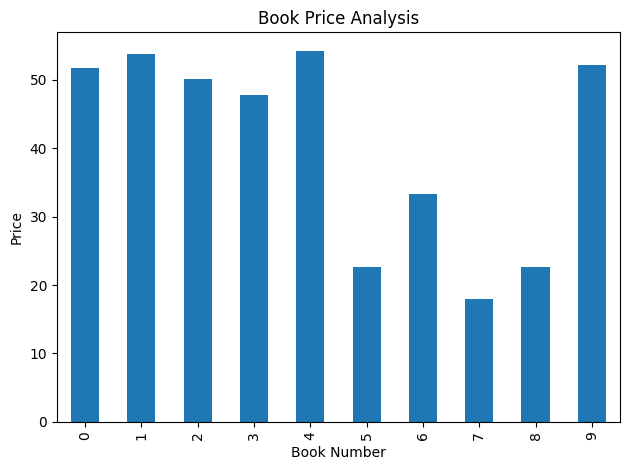

In [7]:

if price_col:
    df[price_col].dropna().head(10).plot(kind="bar")

    plt.title("Book Price Analysis")
    plt.xlabel("Book Number")
    plt.ylabel("Price")
    plt.tight_layout()
    plt.show()
else:
    print("No price column found. Check Step 2.")


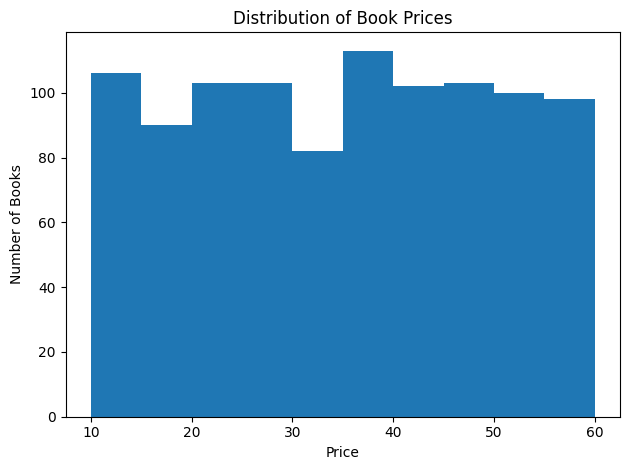

In [8]:

if price_col:
    plt.hist(df[price_col].dropna(), bins=10)

    plt.title("Distribution of Book Prices")
    plt.xlabel("Price")
    plt.ylabel("Number of Books")
    plt.tight_layout()
    plt.show()


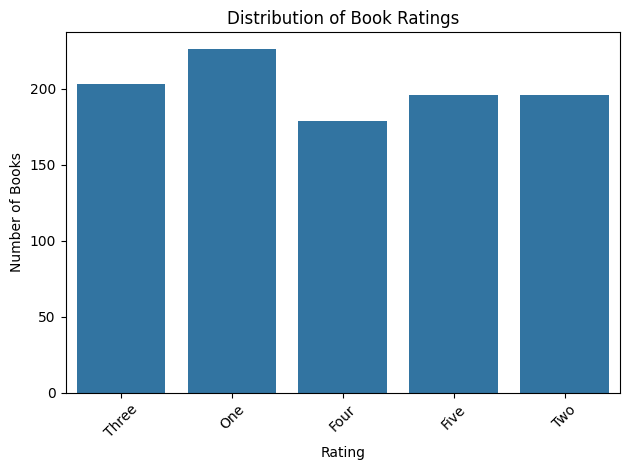

In [9]:

if rating_col:
    sns.countplot(data=df, x=rating_col)

    plt.title("Distribution of Book Ratings")
    plt.xlabel("Rating")
    plt.ylabel("Number of Books")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No rating column found in the dataset.")


In [10]:

print("DATA INSIGHTS")

print("Total number of books:", len(df))

if price_col:
    print("Average book price:",
          round(df[price_col].mean(), 2))
    print("Highest book price:", df[price_col].max())
    print("Lowest book price:", df[price_col].min())

if rating_col:
    print("\nBook rating counts:")
    print(df[rating_col].value_counts())


DATA INSIGHTS
Total number of books: 1000
Average book price: 35.07
Highest book price: 59.99
Lowest book price: 10.0

Book rating counts:
Rating
One      226
Three    203
Five     196
Two      196
Four     179
Name: count, dtype: int64


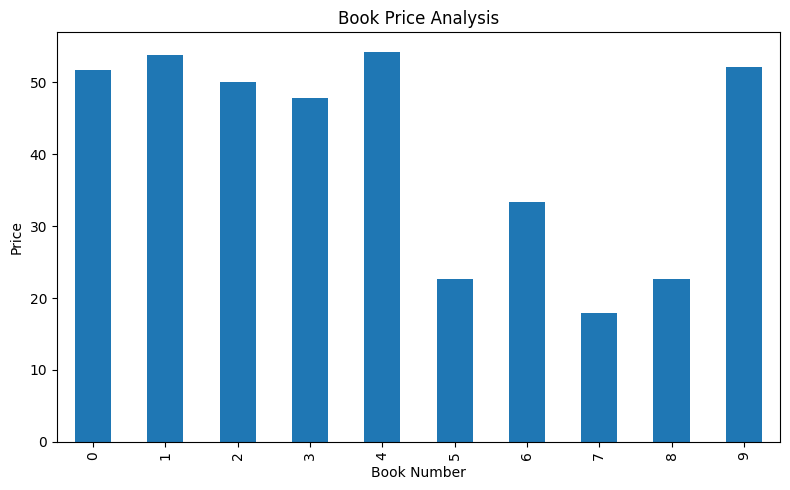

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:

if price_col:
    plt.figure(figsize=(8, 5))
    df[price_col].dropna().head(10).plot(kind="bar")

    plt.title("Book Price Analysis")
    plt.xlabel("Book Number")
    plt.ylabel("Price")
    plt.tight_layout()

    plt.savefig("CodeAlpha_Task3_Book_Prices.png", dpi=300)
    plt.show()

    files.download("CodeAlpha_Task3_Book_Prices.png")


### Key Insights

1. Book prices vary across the dataset, with some books priced higher than others.
2. The histogram helps us understand the distribution of book prices.
3. The rating chart shows that the number of books differs across rating categories.
4. These visualizations make it easier to understand book data and compare prices and ratings.

### Conclusion

In this task, I used Python, Pandas, Matplotlib, and Seaborn to visualize book data. I created different charts to understand book prices and ratings. This project helped me learn how to present data visually and identify useful patterns.